In [57]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [58]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [59]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [60]:
print(df.shape)

(7043, 21)


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [62]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [63]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values[missing_values > 0])

Missing values in each column:


Series([], dtype: int64)

In [64]:
# Check blank strings
blank_values = (
    df.select_dtypes(include="object")
      .apply(lambda col: col.str.strip().eq("").sum())
)

print("Blank values:")
display(blank_values[blank_values > 0])

Blank values:


TotalCharges    11
dtype: int64

In [65]:
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate customer IDs:",
    df["customerID"].duplicated().sum()
)

Total duplicate rows: 0
Duplicate customer IDs: 0


In [66]:
blank_rows = df[
    df["TotalCharges"].astype(str).str.strip() == ""
]

display(blank_rows)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [67]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [68]:
missing = df[df["TotalCharges"].isna()]

display(
    missing[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]
)

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [69]:
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0

In [70]:
# Display column names and data types
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.values,
        "Unique Values": df.nunique().values
    })
)

,Column,Data Type,Unique Values
0,customerID,str,7043
1,gender,str,2
2,SeniorCitizen,int64,2
3,Partner,str,2
4,Dependents,str,2
5,tenure,int64,73
6,PhoneService,str,2
7,MultipleLines,str,3
8,InternetService,str,3
9,OnlineSecurity,str,3


In [71]:
churn_counts = df["Churn"].value_counts()
display(churn_counts)
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

display(churn_percentage.round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

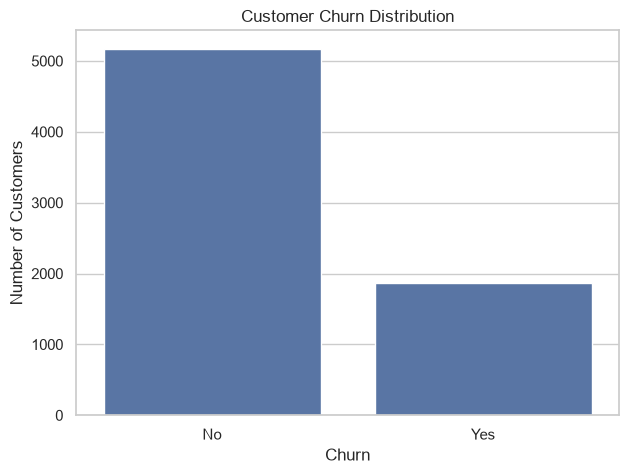

In [72]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [73]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


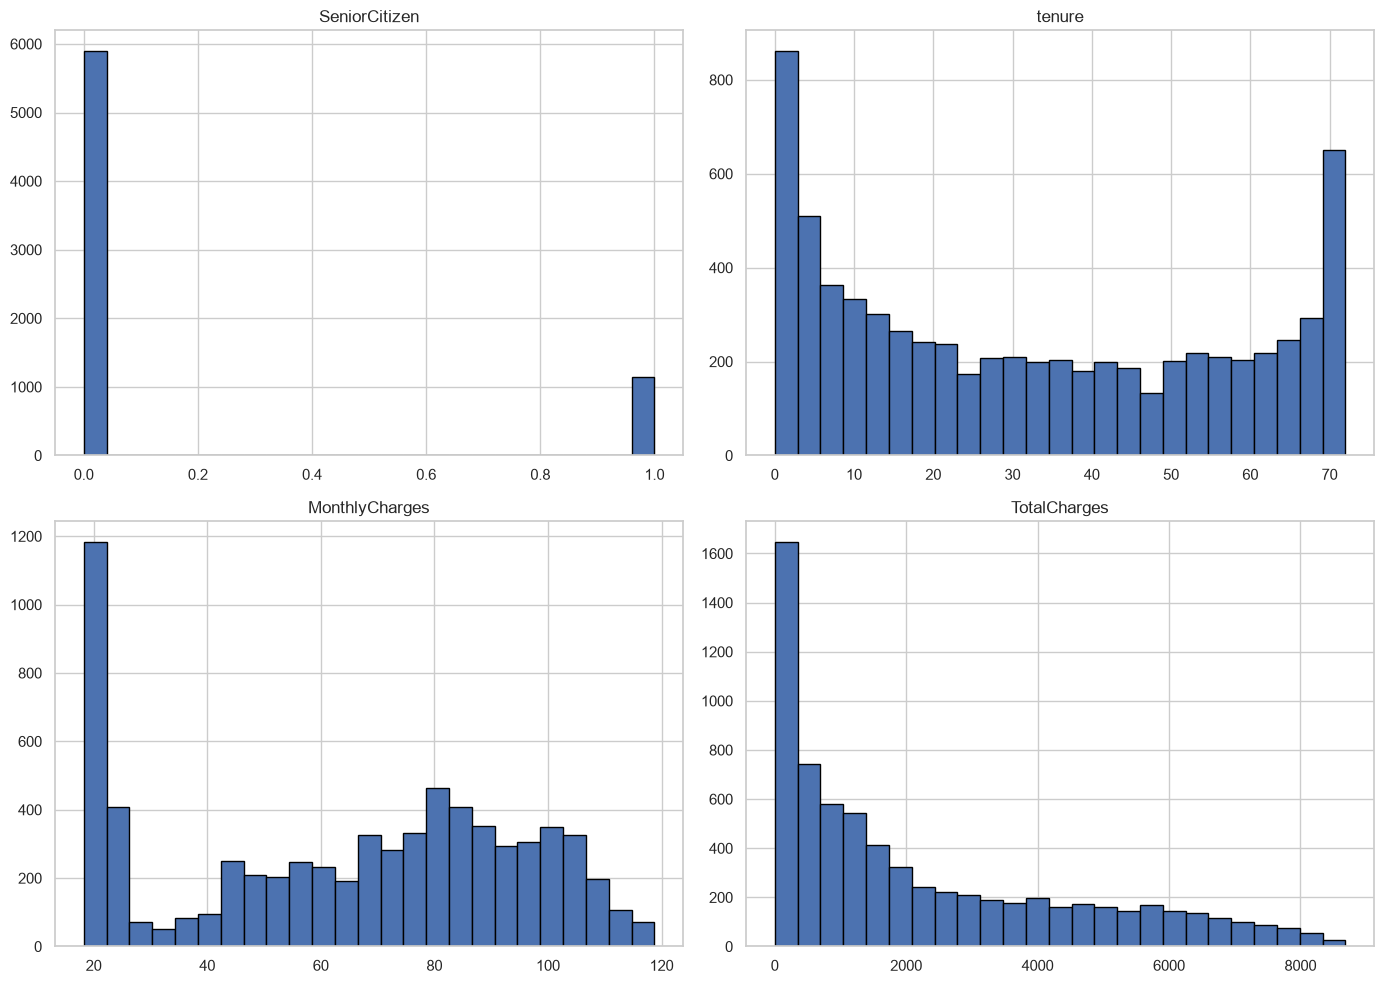

In [74]:
df[numerical_columns].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

In [75]:
skewness = df[numerical_columns].skew()

display(
    skewness.sort_values(ascending=False).to_frame("Skewness")
)

,Skewness
SeniorCitizen,1.833633
TotalCharges,0.963235
tenure,0.239540
MonthlyCharges,-0.220524


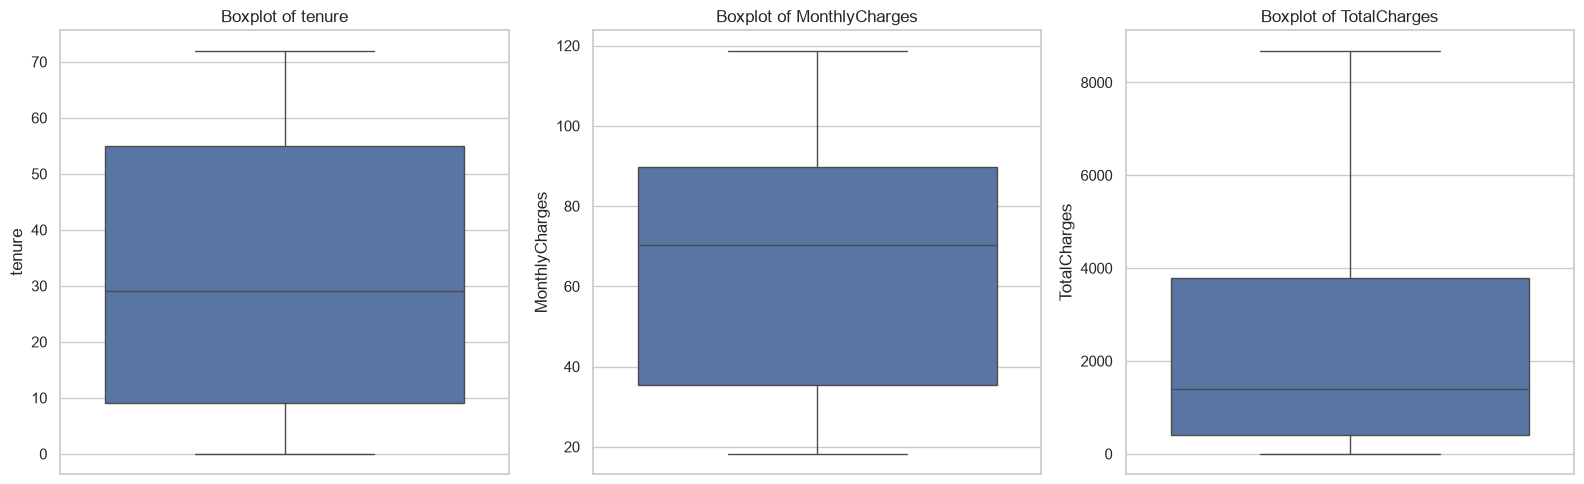

In [76]:
numerical_columns = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(numerical_columns, axes):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

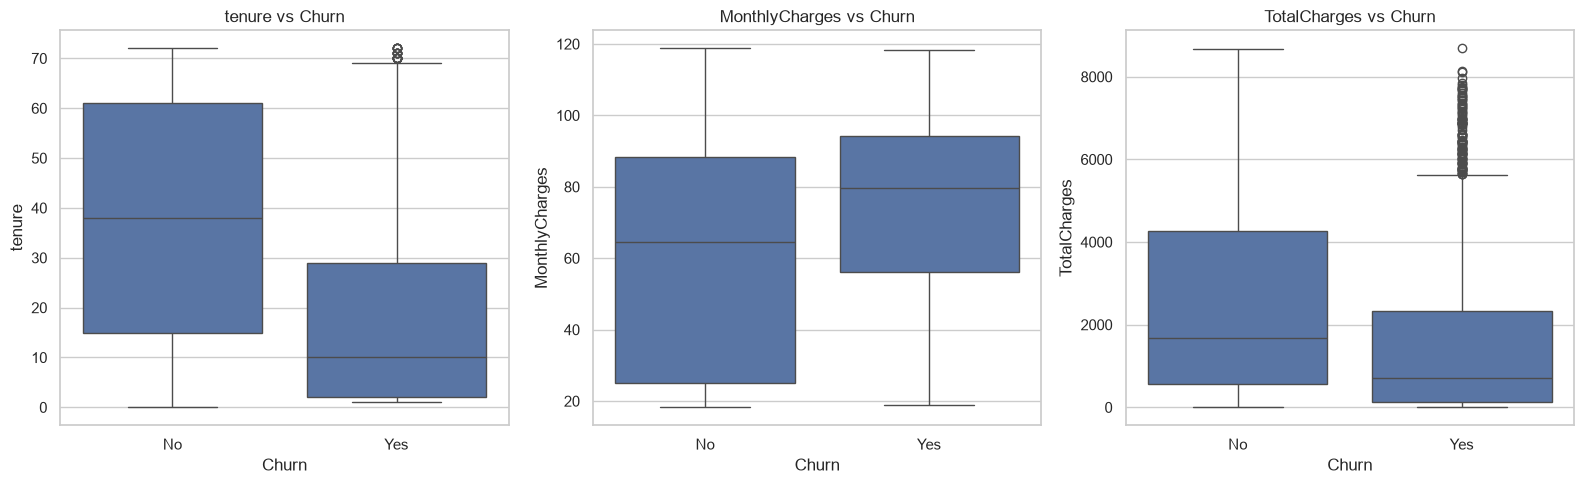

In [77]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(numerical_features, axes):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax)
    ax.set_title(f"{col} vs Churn")

plt.tight_layout()
plt.show()

In [78]:
monthly_stats = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "std", "min", "max"]
)

display(monthly_stats)

,mean,median,std,min,max
Churn,,,,,
No,61.265124,64.425,31.092648,18.25,118.75
Yes,74.441332,79.650,24.666053,18.85,118.35


In [79]:
from scipy.stats import mannwhitneyu

stayed = df.loc[df["Churn"] == "No", "MonthlyCharges"]
churned = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]

stat, p_value = mannwhitneyu(
    stayed,
    churned,
    alternative="two-sided"
)

print("U Statistic:", stat)
print("P-value:", p_value)

U Statistic: 3667080.5
P-value: 3.311627651988585e-54


In [80]:
from scipy.stats import mannwhitneyu

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

results = []

for col in numerical_features:

    group_no = df[df["Churn"] == "No"][col]
    group_yes = df[df["Churn"] == "Yes"][col]

    u_stat, p_value = mannwhitneyu(
        group_no,
        group_yes,
        alternative="two-sided"
    )

    results.append({
        "Feature": col,
        "U Statistic": u_stat,
        "P-value": p_value,
        "Significant": p_value < 0.05,
        "Median (No)": group_no.median(),
        "Median (Yes)": group_yes.median()
    })

mw_results = pd.DataFrame(results)

display(mw_results)

,Feature,U Statistic,P-value,Significant,Median (No),Median (Yes)
0,tenure,7154668.0,2.419636e-208,True,38.000,10.00
1,MonthlyCharges,3667080.5,3.311628e-54,True,64.425,79.65
2,TotalCharges,6288982.0,5.685034e-83,True,1679.525,703.55


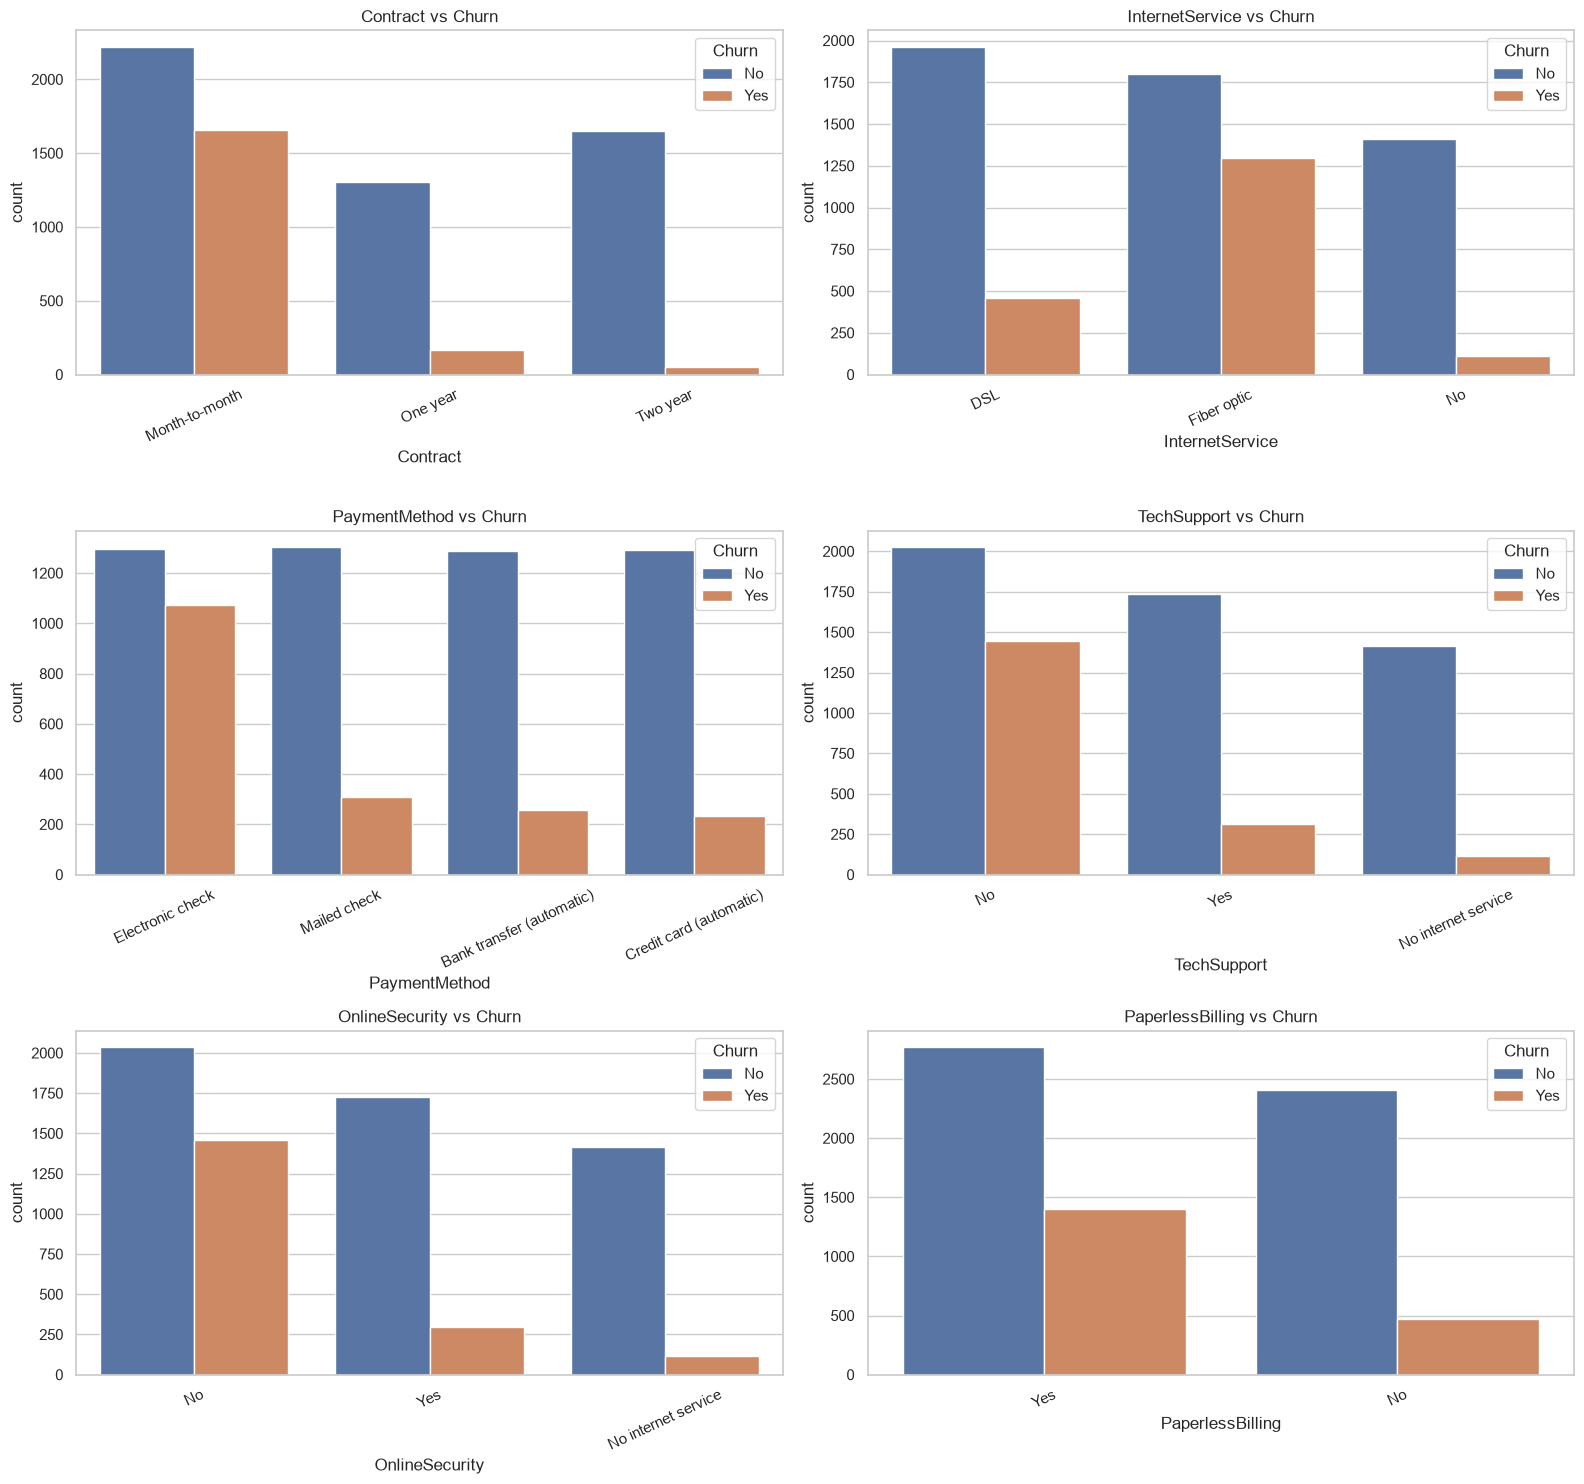

In [81]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for col, ax in zip(categorical_features, axes.flatten()):
    sns.countplot(
        data=df,
        x=col,
        hue="Churn",
        ax=ax
    )
    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [82]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling"
]

churn_summary = []

for col in categorical_features:

    rates = df.groupby(col, observed=True)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    for category, rate in rates.items():
        churn_summary.append({
            "Feature": col,
            "Category": category,
            "Churn_Rate": rate
        })

churn_summary = pd.DataFrame(churn_summary)

display(
    churn_summary.sort_values(
        "Churn_Rate", ascending=False
    ).round(2)
)

,Feature,Category,Churn_Rate
8,PaymentMethod,Electronic check,45.29
0,Contract,Month-to-month,42.71
4,InternetService,Fiber optic,41.89
13,OnlineSecurity,No,41.77
10,TechSupport,No,41.64
17,PaperlessBilling,Yes,33.57
9,PaymentMethod,Mailed check,19.11
3,InternetService,DSL,18.96
6,PaymentMethod,Bank transfer (automatic),16.71
16,PaperlessBilling,No,16.33


In [83]:
from scipy.stats import chi2_contingency

chi_results = []

for col in categorical_features:

    contingency_table = pd.crosstab(df[col], df["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        "Feature": col,
        "Chi2 Statistic": chi2,
        "P-value": p_value,
        "Degrees of Freedom": dof,
        "Significant": p_value < 0.05
    })

chi_df = pd.DataFrame(chi_results)

display(
    chi_df.sort_values("P-value").reset_index(drop=True)
)

,Feature,Chi2 Statistic,P-value,Degrees of Freedom,Significant
0,Contract,1184.596572,5.863038e-258,2,True
1,OnlineSecurity,849.998968,2.661150e-185,2,True
2,TechSupport,828.197068,1.443084e-180,2,True
3,InternetService,732.309590,9.571788e-160,2,True
4,PaymentMethod,648.142327,3.682355e-140,3,True
5,PaperlessBilling,258.277649,4.073355e-58,1,True


                SeniorCitizen    tenure  MonthlyCharges  TotalCharges
SeniorCitizen        1.000000  0.016567        0.220173      0.103006
tenure               0.016567  1.000000        0.247900      0.826178
MonthlyCharges       0.220173  0.247900        1.000000      0.651174
TotalCharges         0.103006  0.826178        0.651174      1.000000


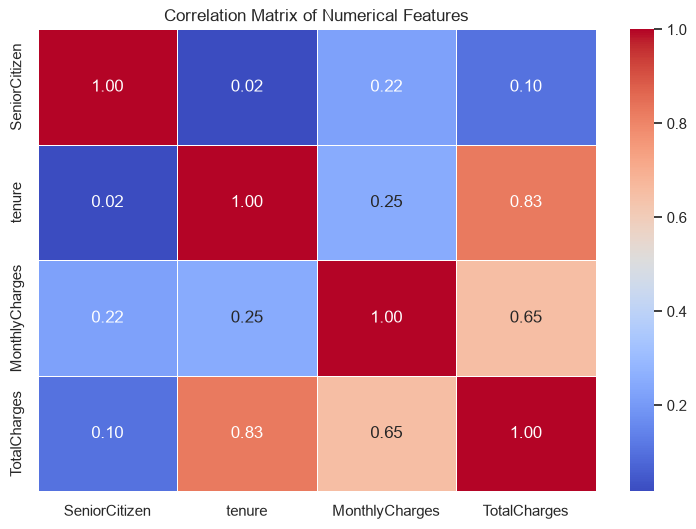

In [ ]:
numerical_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

correlation_matrix = df[numerical_features].corr(
    method="pearson"
)

print(correlation_matrix)
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

## Multicollinearity Analysis

Multicollinearity occurs when independent variables
are highly correlated with each other.

We use Variance Inflation Factor (VIF) to identify
potential multicollinearity among numerical features.

In [85]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

X_vif = df[vif_features].copy()

X_vif = add_constant(X_vif)

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
4,TotalCharges,9.528163
2,tenure,5.839368
3,MonthlyCharges,3.306036
1,SeniorCitizen,1.054557
0,const,1.000000


**Feature Engineering**

In [86]:
df["AverageMonthlySpend"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    0
)

In [87]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New Customer",
        "Short Term",
        "Medium Term",
        "Long Term"
    ]
)

In [88]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["TotalServices"] = df[service_columns].apply(
    lambda row: sum(value == "Yes" for value in row),
    axis=1
)

In [89]:
df["HasSupport"] = (
    df["TechSupport"] == "Yes"
).astype(int)

df["HasSecurity"] = (
    df["OnlineSecurity"] == "Yes"
).astype(int)

In [90]:
median_charges = df["MonthlyCharges"].median()

df["HighCharges"] = (
    df["MonthlyCharges"] > median_charges
).astype(int)

In [91]:
new_features = [
    "AverageMonthlySpend",
    "TenureGroup",
    "TotalServices",
    "HasSupport",
    "HasSecurity",
    "HighCharges"
]

display(df[new_features].head(10))

display(df[new_features].describe(include="all"))

,AverageMonthlySpend,TenureGroup,TotalServices,HasSupport,HasSecurity,HighCharges
0,29.850000,New Customer,1,0,0,0
1,55.573529,Medium Term,3,0,1,0
2,54.075000,New Customer,3,0,1,0
3,40.905556,Medium Term,3,1,1,0
4,75.825000,New Customer,1,0,0,1
5,102.562500,New Customer,5,0,0,1
6,88.609091,Short Term,4,0,0,1
7,30.190000,New Customer,1,0,1,0
8,108.787500,Medium Term,6,1,0,1
9,56.257258,Long Term,3,0,1,0


,AverageMonthlySpend,TenureGroup,TotalServices,HasSupport,HasSecurity,HighCharges
count,7043.000000,7043,7043.000000,7043.000000,7043.000000,7043.000000
unique,NaN,4,NaN,NaN,NaN,NaN
top,NaN,Long Term,NaN,NaN,NaN,NaN
freq,NaN,2239,NaN,NaN,NaN,NaN
mean,64.698218,NaN,3.362914,0.290217,0.286668,0.499077
std,30.270670,NaN,2.062031,0.453895,0.452237,0.500035
min,0.000000,NaN,0.000000,0.000000,0.000000,0.000000
25%,35.649000,NaN,1.000000,0.000000,0.000000,0.000000
50%,70.300000,NaN,3.000000,0.000000,0.000000,0.000000
75%,90.174158,NaN,5.000000,1.000000,1.000000,1.000000


In [92]:
engineered_features = [
    "TenureGroup",
    "TotalServices",
    "HasSupport",
    "HasSecurity",
    "HighCharges"
]

for col in engineered_features:

    print(f"\nChurn rate by {col}")

    result = (
        df.groupby(col, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    display(result.round(2))


Churn rate by TenureGroup


TenureGroup
New Customer    47.44
Short Term      28.71
Medium Term     20.39
Long Term        9.51
Name: Churn, dtype: float64


Churn rate by TotalServices


TotalServices
0    43.75
3    36.48
2    32.83
4    31.34
5    25.55
6    22.49
1    21.11
7    12.41
8     5.29
Name: Churn, dtype: float64


Churn rate by HasSupport


HasSupport
0    31.19
1    15.17
Name: Churn, dtype: float64


Churn rate by HasSecurity


HasSecurity
0    31.33
1    14.61
Name: Churn, dtype: float64


Churn rate by HighCharges


HighCharges
1    35.19
0    17.91
Name: Churn, dtype: float64


## Chi-Square Test Metrics

- **Chi-square (χ²):** Measures the difference between observed and expected frequencies.
- **P-value:** Determines whether the association is statistically significant (p < 0.05).
- **Cramér's V:** Measures the strength of association between categorical variables (0 to 1).
- **Degrees of Freedom (DOF):** Determines the reference Chi-square distribution, calculated as (Rows - 1) × (Columns - 1).


In [93]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "TenureGroup",
    "HasSupport",
    "HasSecurity",
    "HighCharges",
    "TotalServices"
]

chi_results = []

for col in categorical_features:

    contingency_table = pd.crosstab(df[col], df["Churn"])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.values.sum()
    min_dim = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(chi2 / (n * min_dim))

    chi_results.append({
        "Feature": col,
        "Chi2": chi2,
        "P_Value": p_value,
        "Cramers_V": cramers_v,
        "Degrees_of_Freedom": dof
    })

chi_results_df = pd.DataFrame(chi_results)

display(
    chi_results_df.sort_values(
        "Cramers_V", ascending=False
    ).round(5)
)

,Feature,Chi2,P_Value,Cramers_V,Degrees_of_Freedom
0,Contract,1184.59657,0.0,0.41012,2
6,TenureGroup,856.10024,0.0,0.34865,3
4,OnlineSecurity,849.99897,0.0,0.34740,2
3,TechSupport,828.19707,0.0,0.34292,2
1,InternetService,732.30959,0.0,0.32245,2
2,PaymentMethod,648.14233,0.0,0.30336,3
9,HighCharges,268.74738,0.0,0.19534,1
5,PaperlessBilling,258.27765,0.0,0.19150,1
10,TotalServices,216.64290,0.0,0.17539,8
8,HasSecurity,205.63310,0.0,0.17087,1


## Statistical Analysis – Chi-Square Test

### Objective
To identify significant associations between categorical features and customer churn.

### Hypotheses
- **H₀:** No association exists between the feature and churn.
- **H₁:** An association exists between the feature and churn.

Significance level: α = 0.05.

### Key Findings
- **Contract (0.410):** Strongest association with churn.
- **TenureGroup (0.349):** New customers show higher churn.
- **OnlineSecurity (0.347):** Security subscription is associated with lower churn.
- **TechSupport (0.343):** Customers without support show higher churn.
- **InternetService (0.322):** Churn varies across internet service types.
- **PaymentMethod (0.303):** Electronic check customers show higher churn.

All 11 features showed statistically significant associations (p < 0.05).

### Conclusion
Contract type, customer tenure, online security and technical support are among the most important categorical features associated with customer churn. These findings will guide further feature selection and machine learning.

*Note: Statistical association does not imply causation.*

**Benjamini–Hochberg correction**

In [94]:
from statsmodels.stats.multitest import multipletests

# Extract original p-values
p_values = chi_results_df["P_Value"].astype(float)

# Apply Benjamini-Hochberg correction
reject, adjusted_pvalues, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)


chi_results_df["Adjusted_P_Value"] = adjusted_pvalues
chi_results_df["Significant_After_BH"] = reject

display(
    chi_results_df.sort_values(
        "Adjusted_P_Value"
    ).round(6)
)

,Feature,Chi2,P_Value,Cramers_V,Degrees_of_Freedom,Adjusted_P_Value,Significant_After_BH
0,Contract,1184.596572,0.0,0.410116,2,0.0,True
4,OnlineSecurity,849.998968,0.0,0.347400,2,0.0,True
6,TenureGroup,856.100239,0.0,0.348645,3,0.0,True
3,TechSupport,828.197068,0.0,0.342916,2,0.0,True
1,InternetService,732.309590,0.0,0.322455,2,0.0,True
2,PaymentMethod,648.142327,0.0,0.303359,3,0.0,True
9,HighCharges,268.747381,0.0,0.195341,1,0.0,True
5,PaperlessBilling,258.277649,0.0,0.191498,1,0.0,True
8,HasSecurity,205.633104,0.0,0.170871,1,0.0,True
7,HasSupport,190.166842,0.0,0.164319,1,0.0,True


## Benjamini–Hochberg Multiple Testing Correction

### Objective
Applied the Benjamini–Hochberg procedure to control the False Discovery Rate (FDR) when testing multiple categorical features.

### Key Findings
- All 11 features remained statistically significant after BH correction (adjusted p-value < 0.05).
- Contract showed the strongest association with churn (Cramér's V = 0.410).
- TenureGroup, OnlineSecurity and TechSupport also showed relatively strong associations.
- HasSupport and HasSecurity showed comparatively weaker associations.

### Conclusion
All investigated categorical features showed statistically significant associations with customer churn even after multiple-testing correction. Contract type was the strongest associated feature.

In [95]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Features:")
print(numerical_columns)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AverageMonthlySpend', 'TotalServices', 'HasSupport', 'HasSecurity', 'HighCharges']


In [96]:
correlation_matrix = df[numerical_columns].corr(method="pearson")

display(correlation_matrix.round(3))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,AverageMonthlySpend,TotalServices,HasSupport,HasSecurity,HighCharges
SeniorCitizen,1.000,0.017,0.220,0.103,0.218,0.096,-0.061,-0.039,0.211
tenure,0.017,1.000,0.248,0.826,0.249,0.524,0.324,0.327,0.197
MonthlyCharges,0.220,0.248,1.000,0.651,0.994,0.802,0.338,0.297,0.858
TotalCharges,0.103,0.826,0.651,1.000,0.651,0.796,0.432,0.412,0.534
AverageMonthlySpend,0.218,0.249,0.994,0.651,1.000,0.797,0.336,0.295,0.853
TotalServices,0.096,0.524,0.802,0.796,0.797,1.000,0.584,0.522,0.637
HasSupport,-0.061,0.324,0.338,0.432,0.336,0.584,1.000,0.355,0.201
HasSecurity,-0.039,0.327,0.297,0.412,0.295,0.522,0.355,1.000,0.156
HighCharges,0.211,0.197,0.858,0.534,0.853,0.637,0.201,0.156,1.000


In [97]:
corr_pairs = correlation_matrix.abs()

upper_triangle = corr_pairs.where(
    np.triu(np.ones(corr_pairs.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

high_corr = high_corr[
    high_corr["Correlation"] > 0.70
].sort_values("Correlation", ascending=False)

display(high_corr)

,Feature_1,Feature_2,Correlation
22,MonthlyCharges,AverageMonthlySpend,0.994355
26,MonthlyCharges,HighCharges,0.857835
44,AverageMonthlySpend,HighCharges,0.852818
12,tenure,TotalCharges,0.826178
23,MonthlyCharges,TotalServices,0.802322
41,AverageMonthlySpend,TotalServices,0.797374
32,TotalCharges,TotalServices,0.795854


In [98]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer

# Select numerical predictors, excluding target and identifiers
vif_features = [
    col for col in numerical_columns
    if col not in ["Churn", "SeniorCitizen"]
]

X_vif = df[vif_features].replace([np.inf, -np.inf], np.nan)

# Impute missing values
X_vif = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_vif),
    columns=vif_features
)

vif_data = pd.DataFrame()

vif_data["Feature"] = vif_features

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
1,MonthlyCharges,96.362528
3,AverageMonthlySpend,89.340608
2,TotalCharges,10.318568
4,TotalServices,6.820683
0,tenure,5.887345
7,HighCharges,4.040842
5,HasSupport,1.665105
6,HasSecurity,1.488037


In [99]:
display(
    df[
        [
            "tenure",
            "MonthlyCharges",
            "TotalCharges",
            "AverageMonthlySpend"
        ]
    ].head(15)
)

,tenure,MonthlyCharges,TotalCharges,AverageMonthlySpend
0,1,29.85,29.85,29.850000
1,34,56.95,1889.50,55.573529
2,2,53.85,108.15,54.075000
3,45,42.30,1840.75,40.905556
4,2,70.70,151.65,75.825000
5,8,99.65,820.50,102.562500
6,22,89.10,1949.40,88.609091
7,10,29.75,301.90,30.190000
8,28,104.80,3046.05,108.787500
9,62,56.15,3487.95,56.257258



MonthlyCharges	,	AverageMonthlySpend
here the both are highly corelated so we are dropping avarage montly spending

In [100]:
df = df.drop(columns=["AverageMonthlySpend"])

In [101]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'TenureGroup', 'TotalServices', 'HasSupport', 'HasSecurity', 'HighCharges']


In [102]:
vif_features_reduced = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "TotalServices",
    "HasSupport",
    "HasSecurity",
    "HighCharges"
]

In [103]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer

X_vif_reduced = df[vif_features_reduced].replace(
    [np.inf, -np.inf], np.nan
)

X_vif_reduced = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X_vif_reduced),
    columns=vif_features_reduced
)

vif_reduced = pd.DataFrame({
    "Feature": vif_features_reduced,
    "VIF": [
        variance_inflation_factor(
            X_vif_reduced.values, i
        )
        for i in range(X_vif_reduced.shape[1])
    ]
})

display(
    vif_reduced.sort_values("VIF", ascending=False).round(3)
)

,Feature,VIF
2,TotalCharges,10.276
1,MonthlyCharges,8.561
3,TotalServices,6.811
0,tenure,5.880
6,HighCharges,4.041
4,HasSupport,1.665
5,HasSecurity,1.488


                SeniorCitizen    tenure  MonthlyCharges  TotalCharges  \
SeniorCitizen        1.000000  0.016567        0.220173      0.103006   
tenure               0.016567  1.000000        0.247900      0.826178   
MonthlyCharges       0.220173  0.247900        1.000000      0.651174   
TotalCharges         0.103006  0.826178        0.651174      1.000000   
TotalServices        0.095946  0.523600        0.802322      0.795854   
HasSupport          -0.060625  0.324221        0.338304      0.431883   
HasSecurity         -0.038653  0.327203        0.296594      0.411651   
HighCharges          0.211140  0.196675        0.857835      0.534497   

                TotalServices  HasSupport  HasSecurity  HighCharges  
SeniorCitizen        0.095946   -0.060625    -0.038653     0.211140  
tenure               0.523600    0.324221     0.327203     0.196675  
MonthlyCharges       0.802322    0.338304     0.296594     0.857835  
TotalCharges         0.795854    0.431883     0.411651     0.5

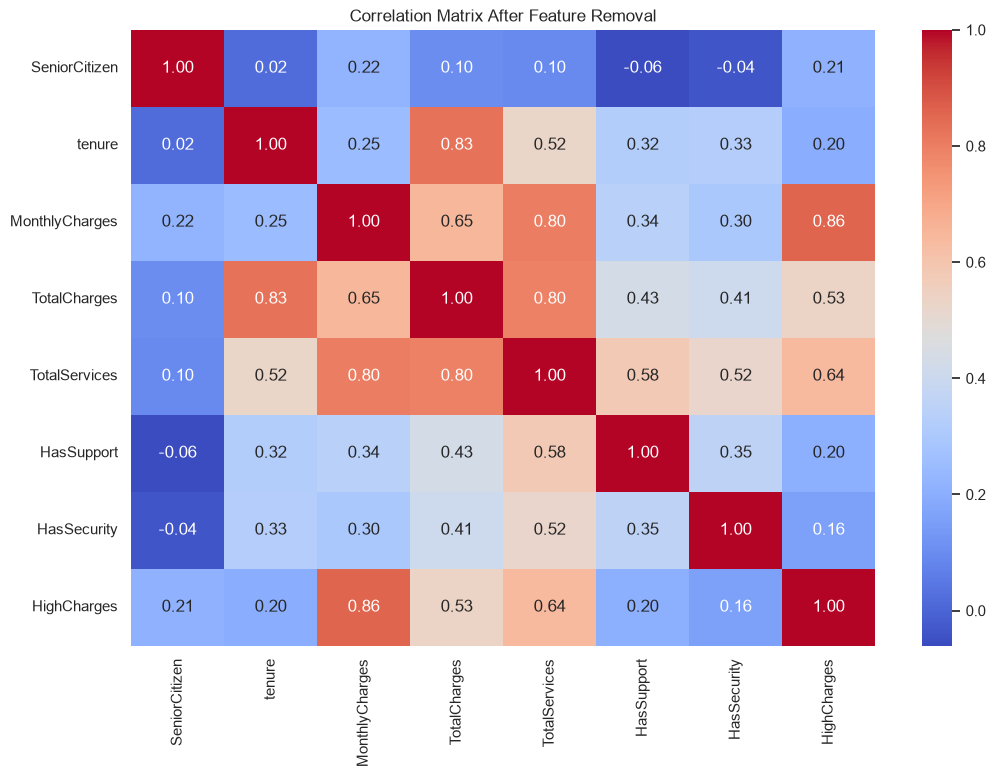

In [104]:
numerical_features = df.select_dtypes(include=["int64", "float64"])

correlation_matrix = numerical_features.corr()
print(correlation_matrix)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix After Feature Removal")
plt.show()

In [105]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = numerical_features.drop(columns=["SeniorCitizen", "Churn"], errors="ignore")

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values("VIF", ascending=False)
display(vif_data)

,Feature,VIF
2,TotalCharges,10.275598
1,MonthlyCharges,8.561400
3,TotalServices,6.811157
0,tenure,5.880073
6,HighCharges,4.040743
4,HasSupport,1.665100
5,HasSecurity,1.488032


In [106]:
df.drop(columns=["HighCharges"], inplace=True)

In [107]:
numerical_features = df.select_dtypes(include=["int64", "float64"])

print(numerical_features.columns.tolist())

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices', 'HasSupport', 'HasSecurity']


In [108]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif = numerical_features.drop(
    columns=["SeniorCitizen"],
    errors="ignore"
)

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

display(vif_data.sort_values("VIF", ascending=False))

,Feature,VIF
2,TotalCharges,10.267817
3,TotalServices,6.801238
0,tenure,5.859748
1,MonthlyCharges,4.867987
4,HasSupport,1.646563
5,HasSecurity,1.460317


In [109]:
from sklearn.preprocessing import LabelEncoder

df["Churn"] = LabelEncoder().fit_transform(df["Churn"])

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

In [110]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd
from sklearn.feature_selection import mutual_info_classif
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd




In [111]:
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]), categorical_cols),

    ("num", SimpleImputer(strategy="median"), numerical_cols)
])

X_encoded = preprocessor.fit_transform(X)

# All encoded categorical columns are discrete.
# Numerical columns are treated as continuous.
discrete_mask = (
    [True] * len(categorical_cols) +
    [False] * len(numerical_cols)
)

print("Encoded shape:", X_encoded.shape)
print("Discrete mask length:", len(discrete_mask))

mi_scores = mutual_info_classif(
    X_encoded,
    y,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": categorical_cols + numerical_cols,
    "MI_Score": mi_scores
}).sort_values("MI_Score", ascending=False)

display(mi_results)

Encoded shape: (7043, 22)
Discrete mask length: 22


,Feature,MI_Score
12,Contract,0.098453
16,tenure,0.072260
6,OnlineSecurity,0.064677
9,TechSupport,0.063021
5,InternetService,0.055574
7,OnlineBackup,0.046792
14,PaymentMethod,0.044519
17,MonthlyCharges,0.044245
8,DeviceProtection,0.043917
18,TotalCharges,0.042704


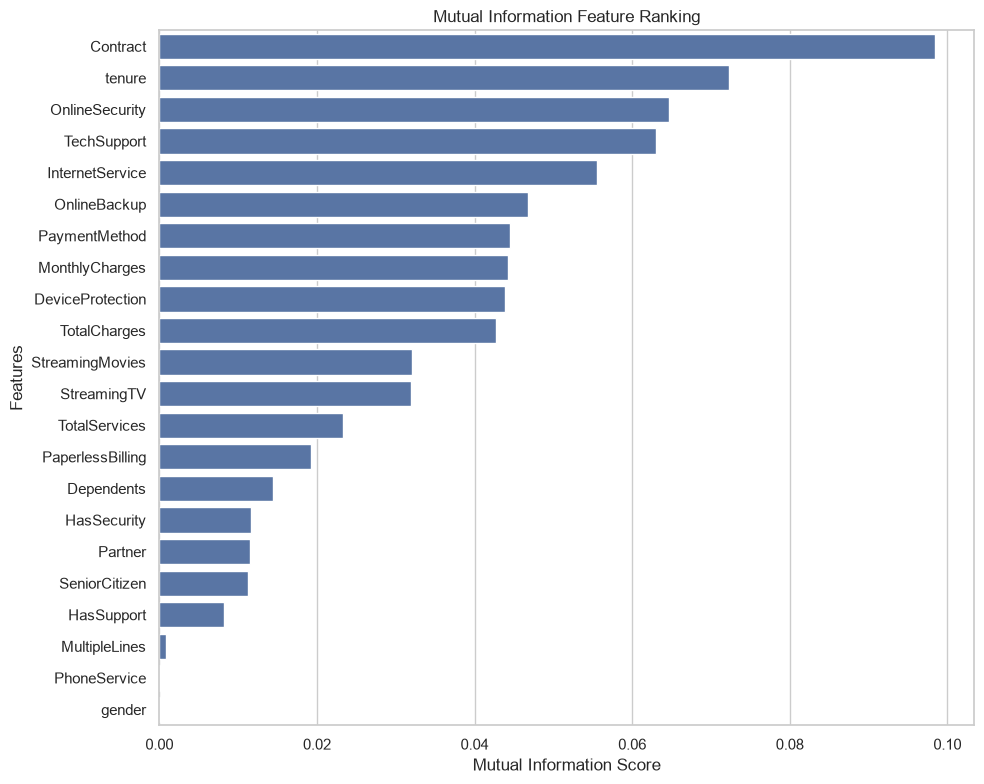

In [112]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.barplot(
    data=mi_results,
    x="MI_Score",
    y="Feature"
)

plt.title("Mutual Information Feature Ranking")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [113]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

In [114]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_pipeline.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'TotalServices','HasSupport', 'HasSecurity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [115]:
import pandas as pd

rf_model = rf_pipeline.named_steps["model"]

feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance
3,num__TotalCharges,0.144140
1,num__tenure,0.128040
2,num__MonthlyCharges,0.120873
39,cat__Contract_Month-to-month,0.070446
30,cat__TechSupport_No,0.031578
41,cat__Contract_Two year,0.029935
21,cat__OnlineSecurity_No,0.029457
4,num__TotalServices,0.028983
46,cat__PaymentMethod_Electronic check,0.025216
19,cat__InternetService_Fiber optic,0.024948


In [116]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [117]:
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'TotalServices','HasSupport', 'HasSecurity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [118]:
from sklearn.inspection import permutation_importance

perm_results = permutation_importance(
    rf_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_results.importances_mean,
    "Std": perm_results.importances_std
}).sort_values("Importance", ascending=False)

display(permutation_df)

,Feature,Importance,Std
14,Contract,0.053710,0.005752
4,tenure,0.019365,0.002023
18,TotalCharges,0.011285,0.002292
7,InternetService,0.010082,0.004517
2,Partner,0.001459,0.001677
1,SeniorCitizen,0.000666,0.001264
3,Dependents,0.000586,0.002132
8,OnlineSecurity,0.000570,0.001839
15,PaperlessBilling,0.000389,0.003593
5,PhoneService,0.000161,0.000638


In [119]:
print(X_train.columns.tolist())
print("Total features:", X_train.shape[1])

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup', 'TotalServices', 'HasSupport', 'HasSecurity']
Total features: 23


In [120]:
full_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
    'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges',
    'TotalCharges', 'TenureGroup', 'TotalServices',
    'HasSupport', 'HasSecurity'
]

reduced_features = [
    col for col in full_features
    if col not in [
        'gender',
        'PhoneService',
        'HasSupport',
        'HasSecurity'
    ]
]

print("Full features:", len(full_features))
print("Reduced features:", len(reduced_features))
print(reduced_features)

Full features: 23
Reduced features: 19
['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'TenureGroup', 'TotalServices']


In [121]:
from sklearn.model_selection import train_test_split

X = df[full_features]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [122]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

def create_pipeline(features):
    X_subset = X_train[features]

    categorical = X_subset.select_dtypes(
        include=["object"]
    ).columns.tolist()

    numerical = X_subset.select_dtypes(
        include=["number"]
    ).columns.tolist()

    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numerical),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ])

In [123]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

feature_sets = {
    "Full Features": full_features,
    "Reduced Features": reduced_features
}

for name, features in feature_sets.items():

    model = create_pipeline(features)

    model.fit(X_train[features], y_train)

    y_pred = model.predict(X_test[features])
    y_prob = model.predict_proba(X_test[features])[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Full Features,0.7644,0.5491,0.6283,0.5860,0.8202
1,Reduced Features,0.7608,0.5437,0.6150,0.5772,0.8215


In [124]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training shape: (5634, 23)
Testing shape: (1409, 23)

Training target distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [125]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

In [126]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'TotalServices','HasSupport', 'HasSecurity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [127]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_pred = lr_pipeline.predict(X_test)
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7331440738112136
Precision: 0.4983164983164983
Recall: 0.7914438502673797
F1 Score: 0.6115702479338843
ROC-AUC: 0.8418378154951045

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



In [128]:
results = []

results.append({
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
})

In [129]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'TotalServices','HasSupport', 'HasSecurity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [130]:
rf_pred = rf_pipeline.predict(X_test)
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1 Score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

results.append(rf_metrics)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



In [131]:
comparison_df = pd.DataFrame(results)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7331,0.4983,0.7914,0.6116,0.8418
1,Random Forest,0.7715,0.5607,0.6417,0.5985,0.8201


In [133]:
print(y_train.value_counts())

Churn
0    4139
1    1495
Name: count, dtype: int64


In [134]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['gender','SeniorCitizen','Partner',...,'TotalServices','HasSupport', 'HasSecurity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthr

In [135]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

xgb_pred = xgb_pipeline.predict(X_test)
xgb_prob = xgb_pipeline.predict_proba(X_test)[:, 1]

xgb_results = {
    "Model": "XGBoost",
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1 Score": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_prob)
}

print(xgb_results)

{'Model': 'XGBoost', 'Accuracy': 0.758694109297374, 'Precision': 0.5309090909090909, 'Recall': 0.7807486631016043, 'F1 Score': 0.6320346320346321, 'ROC-AUC': 0.8416983130538117}


In [136]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(2, 8),
    "model__learning_rate": uniform(0.01, 0.29),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
    "model__min_child_weight": randint(1, 8),
    "model__gamma": uniform(0, 0.5)
}

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV ROC-AUC:", random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'model__colsample_bytree': np.float64(0.782799754606763), 'model__gamma': np.float64(0.1481367528520412), 'model__learning_rate': np.float64(0.05792741232827072), 'model__max_depth': 2, 'model__min_child_weight': 7, 'model__n_estimators': 108, 'model__subsample': np.float64(0.9316734307889971)}
Best CV ROC-AUC: 0.8491252788313475


In [137]:
best_xgb = random_search.best_estimator_

tuned_pred = best_xgb.predict(X_test)
tuned_prob = best_xgb.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, tuned_pred))
print("Precision:", precision_score(y_test, tuned_pred))
print("Recall:", recall_score(y_test, tuned_pred))
print("F1 Score:", f1_score(y_test, tuned_pred))
print("ROC-AUC:", roc_auc_score(y_test, tuned_prob))

Accuracy: 0.8026969481902059
Precision: 0.6678321678321678
Recall: 0.5106951871657754
F1 Score: 0.5787878787878787
ROC-AUC: 0.8460060967733602


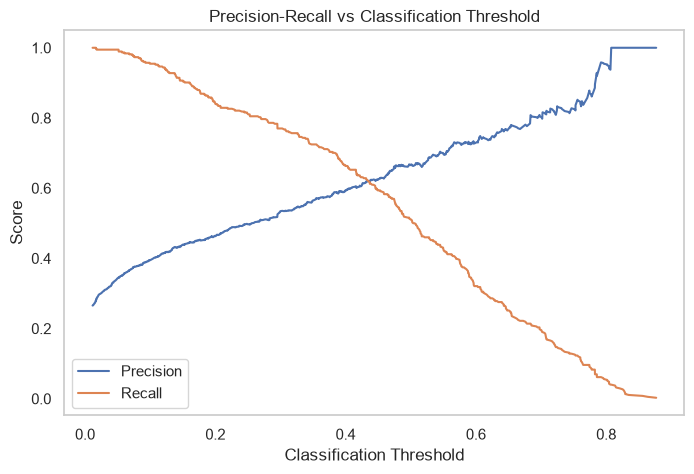

In [138]:
from sklearn.metrics import (
    precision_recall_curve,
    classification_report
)
import matplotlib.pyplot as plt

y_prob = best_xgb.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall vs Classification Threshold")
plt.legend()
plt.grid()
plt.show()

In [139]:
import numpy as np
from sklearn.metrics import precision_recall_curve

y_prob = best_xgb.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold = thresholds[best_idx]

print("Best Threshold:", best_threshold)
print("Best Precision:", precision[best_idx])
print("Best Recall:", recall[best_idx])
print("Best F1 Score:", f1_scores[best_idx])

Best Threshold: 0.38341156
Best Precision: 0.5887640449438202
Best Recall: 0.7005347593582888
Best F1 Score: 0.6398046397550156


In [140]:
from sklearn.metrics import classification_report

y_pred_tuned = (
    y_prob >= best_threshold
).astype(int)

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.88      0.82      0.85      1035
           1       0.59      0.70      0.64       374

    accuracy                           0.79      1409
   macro avg       0.74      0.76      0.75      1409
weighted avg       0.81      0.79      0.80      1409



In [141]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

lr_params = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs"],
    "model__class_weight": [None, "balanced"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

lr_search.fit(X_train, y_train)

best_lr = lr_search.best_estimator_

print("Best LR Parameters:", lr_search.best_params_)
print("Best LR CV ROC-AUC:", lr_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best LR Parameters: {'model__solver': 'lbfgs', 'model__class_weight': None, 'model__C': 10}
Best LR CV ROC-AUC: 0.8465496671509248


In [142]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    "model__n_estimators": [200, 300, 500, 700],
    "model__max_depth": [None, 10, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2", 0.5],
    "model__class_weight": [None, "balanced"]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=25,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_

print("Best RF Parameters:", rf_search.best_params_)
print("Best RF CV ROC-AUC:", rf_search.best_score_)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best RF Parameters: {'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 'log2', 'model__max_depth': 10, 'model__class_weight': None}
Best RF CV ROC-AUC: 0.8448706109430069


In [143]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

results = []

for name, model in models.items():

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.sort_values(
        by="ROC-AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,XGBoost,0.802697,0.667832,0.510695,0.578788,0.846006
0,Logistic Regression,0.795600,0.640523,0.524064,0.576471,0.841616
1,Random Forest,0.801987,0.671480,0.497326,0.571429,0.840608


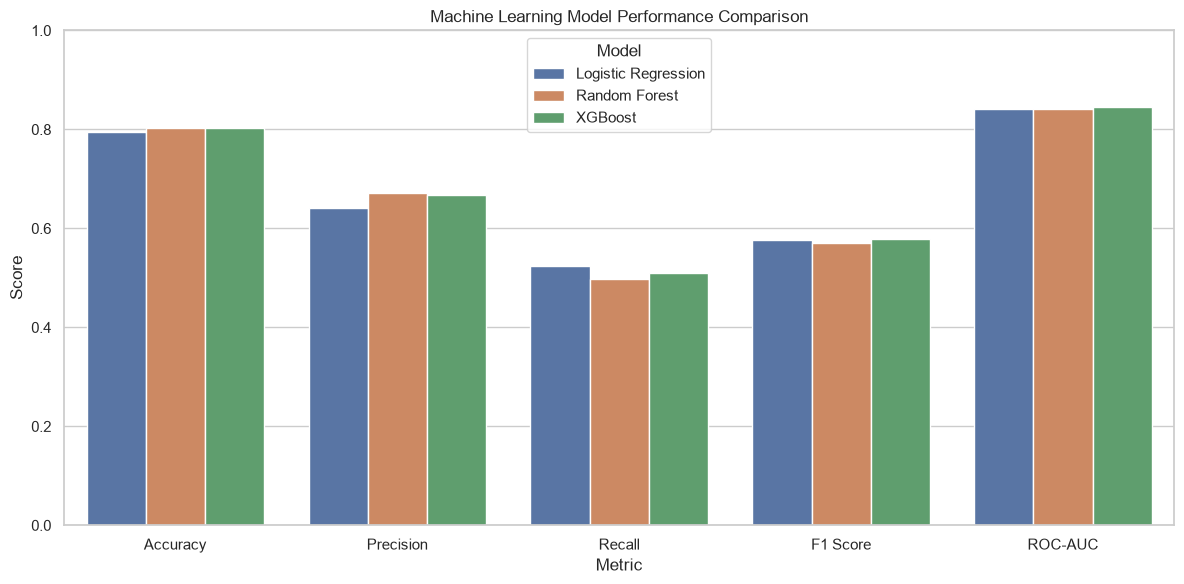

In [144]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [145]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve
import numpy as np

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

models = {
    "Logistic Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

threshold_results = {}
fitted_models = {}

for name, model in models.items():

    model_copy = clone(model)
    model_copy.fit(X_fit, y_fit)

    fitted_models[name] = model_copy

    y_prob = model_copy.predict_proba(X_val)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_val, y_prob
    )

    f1_scores = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-10)
    )

    best_idx = np.argmax(f1_scores)

    threshold_results[name] = {
        "Threshold": thresholds[best_idx],
        "Precision": precision[best_idx],
        "Recall": recall[best_idx],
        "F1 Score": f1_scores[best_idx]
    }

threshold_df = pd.DataFrame(threshold_results).T

display(threshold_df)

,Threshold,Precision,Recall,F1 Score
Logistic Regression,0.415540,0.647059,0.662207,0.654545
Random Forest,0.387937,0.627692,0.682274,0.653846
XGBoost,0.369086,0.607345,0.719064,0.658499


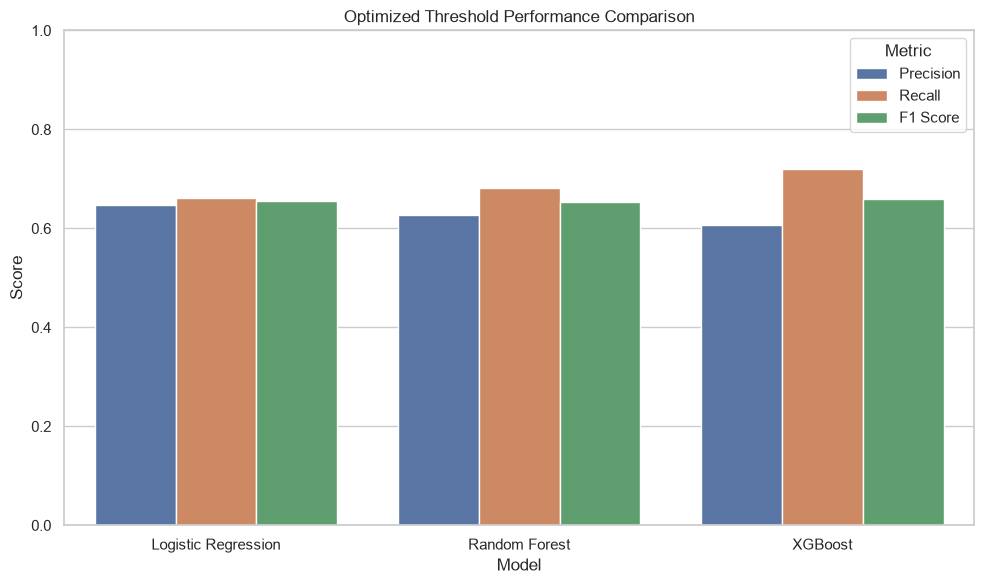

In [146]:
import matplotlib.pyplot as plt
import seaborn as sns

threshold_plot = threshold_df.reset_index(
    names="Model"
).melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=threshold_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Optimized Threshold Performance Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [147]:
display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score
Logistic Regression,0.4155,0.6471,0.6622,0.6545
Random Forest,0.3879,0.6277,0.6823,0.6538
XGBoost,0.3691,0.6073,0.7191,0.6585


In [148]:
from sklearn.metrics import classification_report, roc_auc_score

final_model = fitted_models["XGBoost"]
final_threshold = 0.3691

test_probabilities = final_model.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= final_threshold
).astype(int)

print(classification_report(y_test, final_predictions))

print(
    "ROC-AUC:",
    roc_auc_score(y_test, test_probabilities)
)

              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1035
           1       0.58      0.72      0.64       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.81      0.78      0.79      1409

ROC-AUC: 0.8457219251336898


**WE CONSIDER BEST MODEL AS XGBOOST BY COMPARING 3 MODELS**

In [150]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [151]:
best_xgb = fitted_models["XGBoost"]

xgb_preprocessor = best_xgb.named_steps["preprocessor"]
xgb_model = best_xgb.named_steps["model"]

X_val_transformed = xgb_preprocessor.transform(X_val)

feature_names = xgb_preprocessor.get_feature_names_out()

In [152]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_val_transformed
)

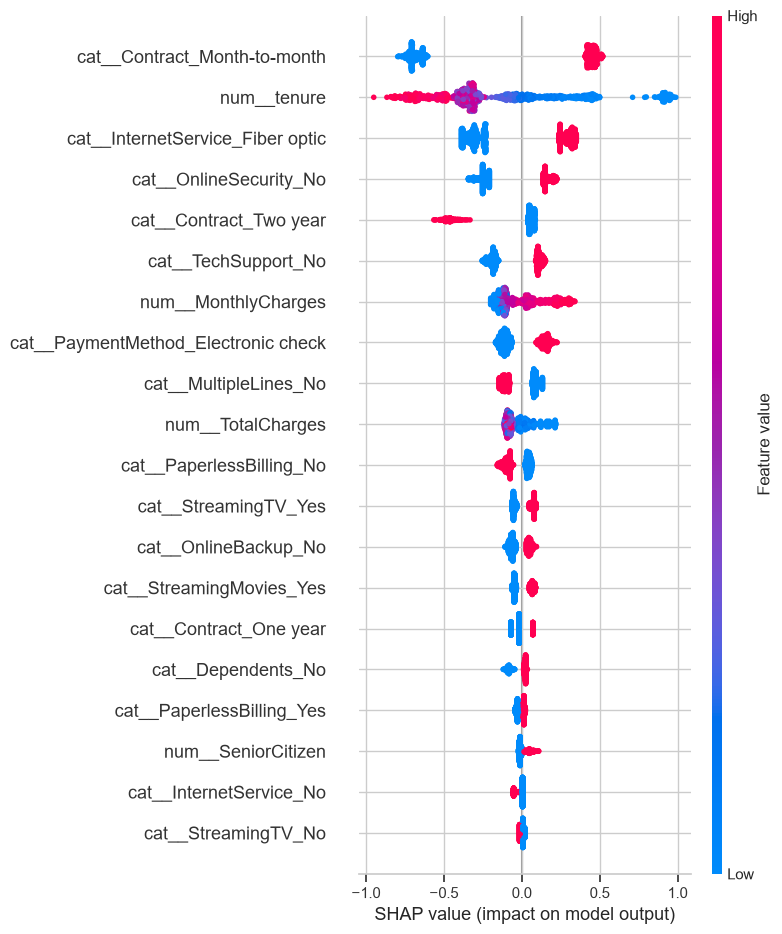

In [153]:
shap.summary_plot(
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    max_display=20
)

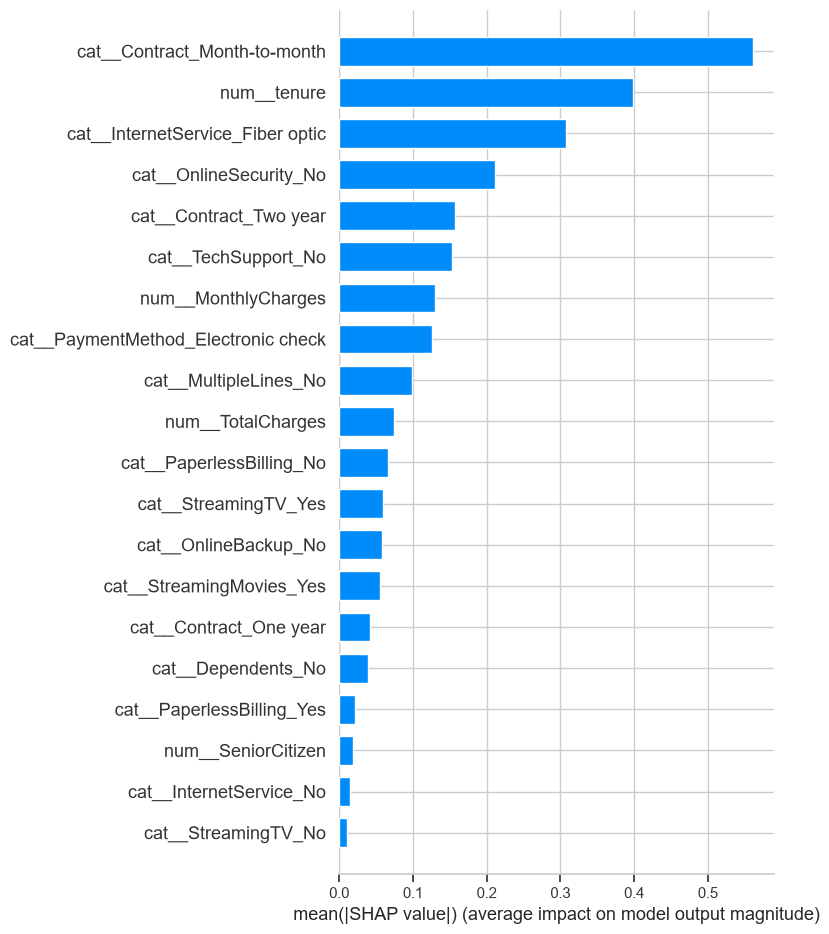

In [154]:
shap.summary_plot(
    shap_values,
    X_val_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20
)

In [156]:
explainer = shap.TreeExplainer(xgb_model)

shap_explanation = explainer(X_val_transformed)

print("SHAP values shape:", shap_explanation.values.shape)
print("Base values:", shap_explanation.base_values)

SHAP values shape: (1127, 52)
Base values: [-1.0335087 -1.0335087 -1.0335087 ... -1.0335087 -1.0335087 -1.0335087]


In [157]:
values = shap_explanation.values
base_values = shap_explanation.base_values

# Handle models returning separate outputs for both classes
if values.ndim == 3:
    values = values[:, :, 1]
    base_values = base_values[:, 1]

shap_exp = shap.Explanation(
    values=values,
    base_values=base_values,
    data=X_val_transformed.toarray()
        if hasattr(X_val_transformed, "toarray")
        else X_val_transformed,
    feature_names=feature_names
)

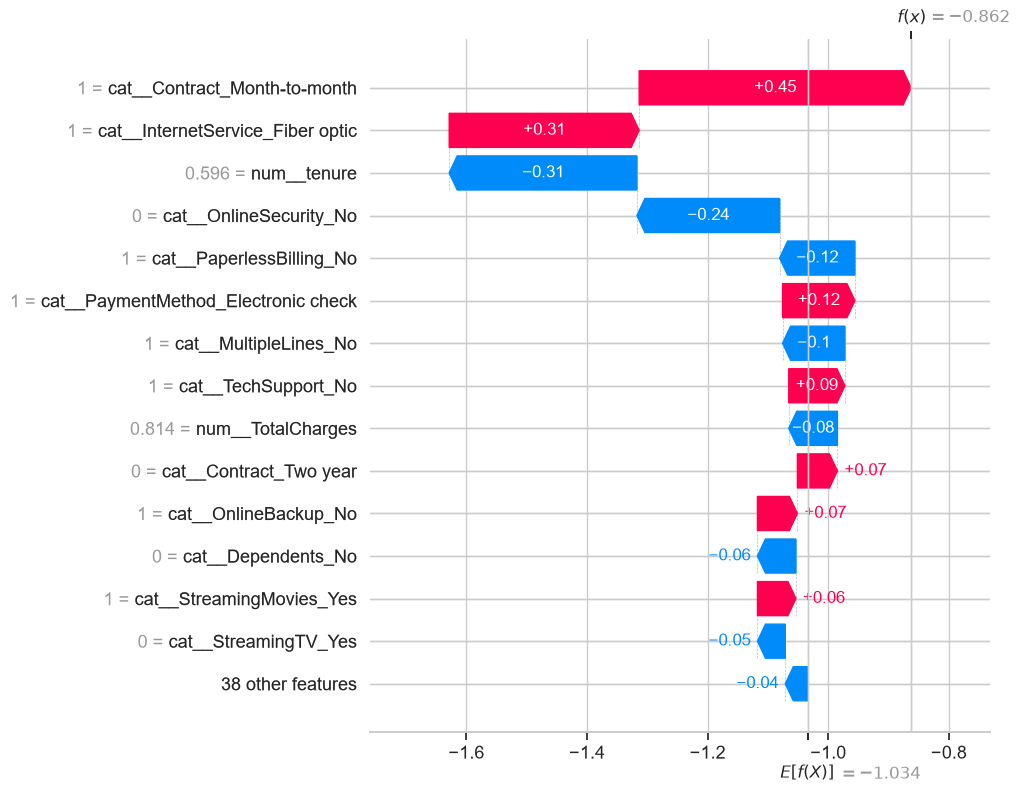

In [158]:
shap.plots.waterfall(shap_exp[0], max_display=15)

In [161]:
X_val_dense = (
    X_val_transformed.toarray()
    if hasattr(X_val_transformed, "toarray")
    else X_val_transformed
)

shap_exp = shap.Explanation(
    values=shap_values,
    base_values=shap_explanation.base_values,
    data=X_val_dense,
    feature_names=feature_names
)

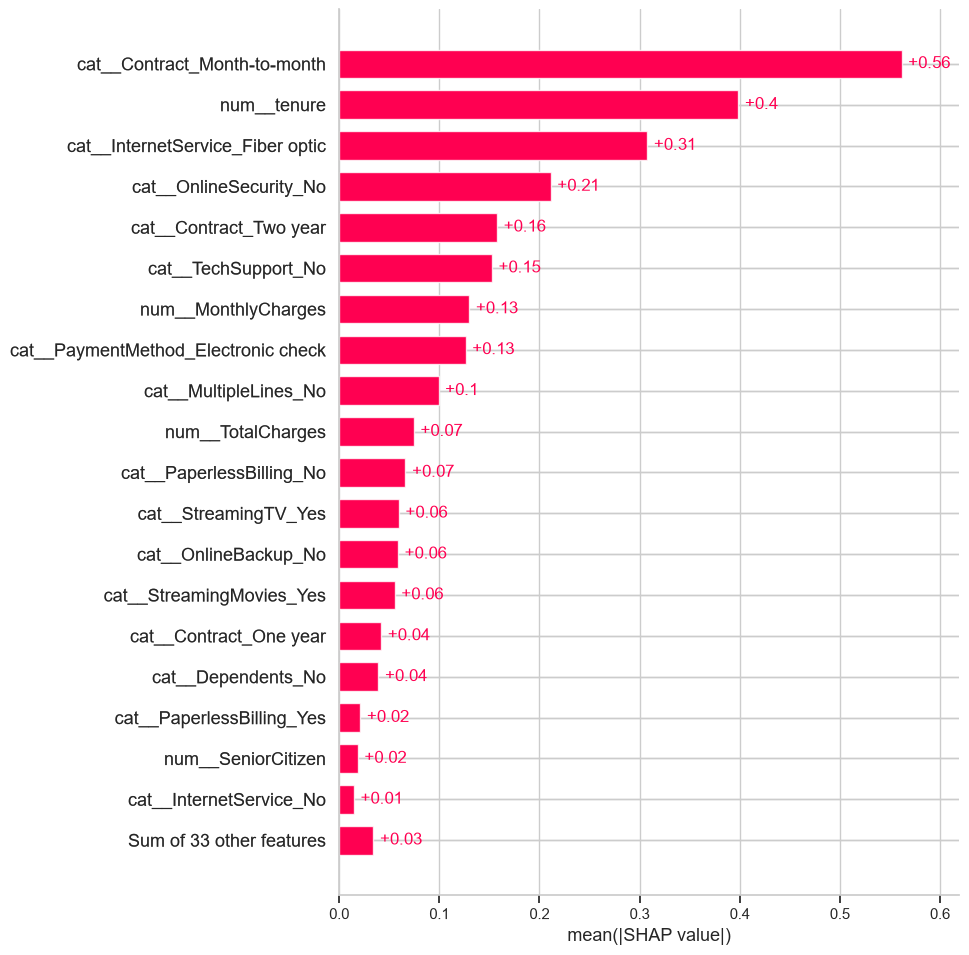

In [162]:
shap.plots.bar(
    shap_exp,
    max_display=20
)

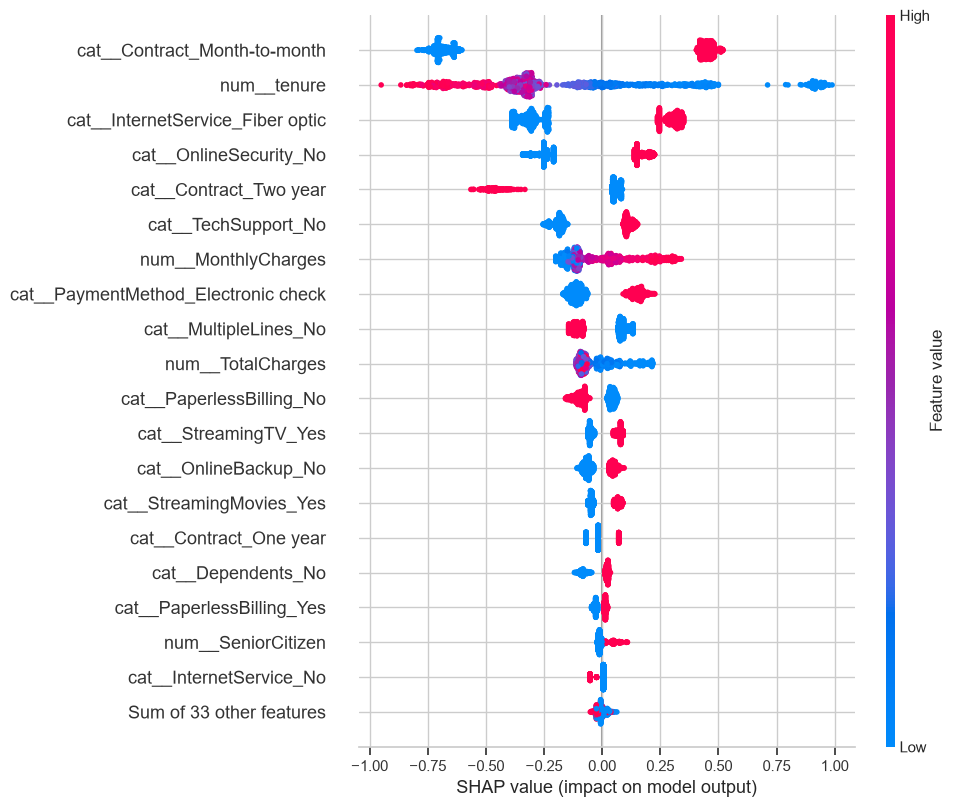

In [163]:
shap.plots.beeswarm(
    shap_exp,
    max_display=20
)

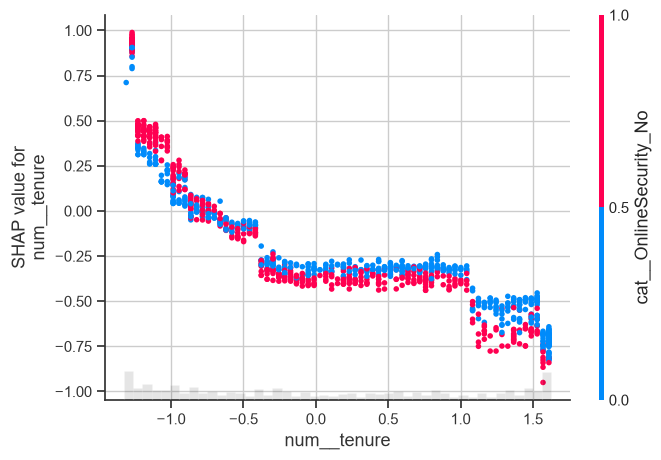

In [164]:
shap.plots.scatter(
    shap_exp[:, "num__tenure"],
    color=shap_exp
)

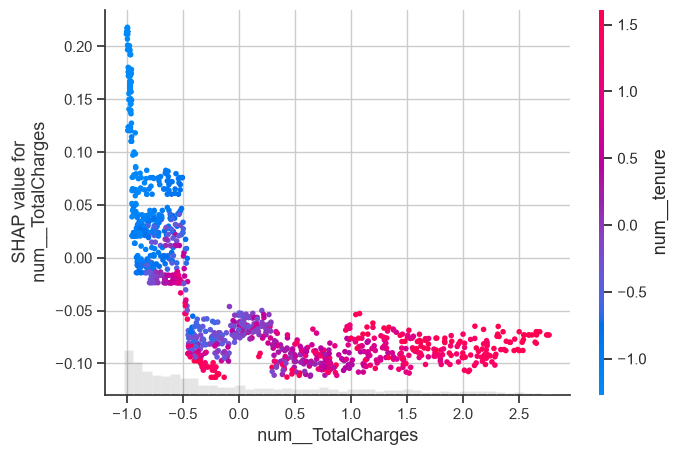

In [165]:
shap.plots.scatter(
    shap_exp[:, "num__TotalCharges"],
    color=shap_exp
)

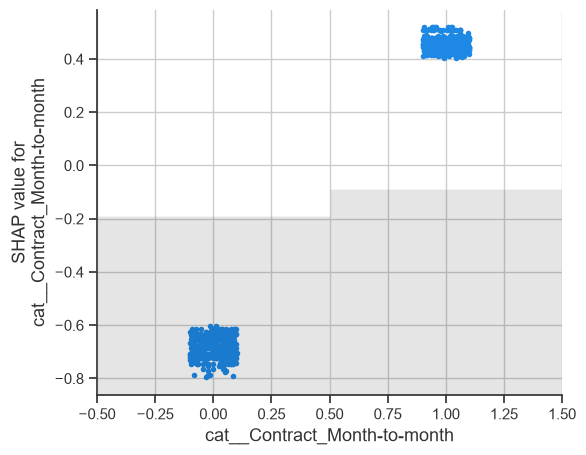

In [166]:
shap.plots.scatter(
    shap_exp[:, "cat__Contract_Month-to-month"]
)

In [167]:
final_model = fitted_models["XGBoost"]

final_threshold = 0.3691

y_prob = final_model.predict_proba(X_test)[:, 1]

y_pred = (y_prob >= final_threshold).astype(int)

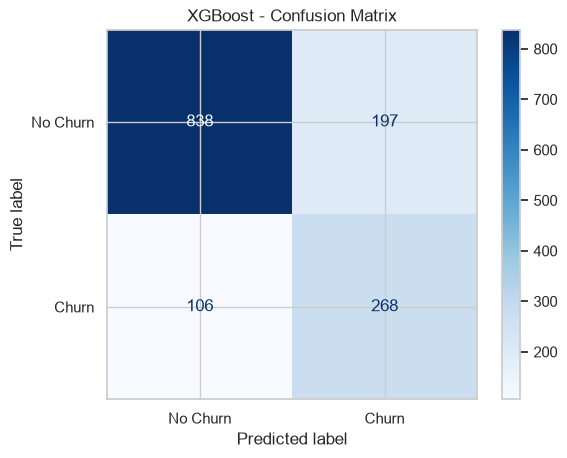

[[838 197]
 [106 268]]


In [168]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost - Confusion Matrix")
plt.show()

print(cm)

The XGBoost classifier was evaluated using the optimized classification threshold of 0.3691. Out of 374 actual churn customers, the model correctly identified 268 customers, achieving approximately 71.66% recall. It missed 106 actual churners and generated 197 false-positive predictions. The results demonstrate that the optimized threshold improves the model's ability to identify customers at risk of churn, although some non-churning customers are also flagged.

In [169]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.89      0.81      0.85      1035
       Churn       0.58      0.72      0.64       374

    accuracy                           0.78      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.81      0.78      0.79      1409



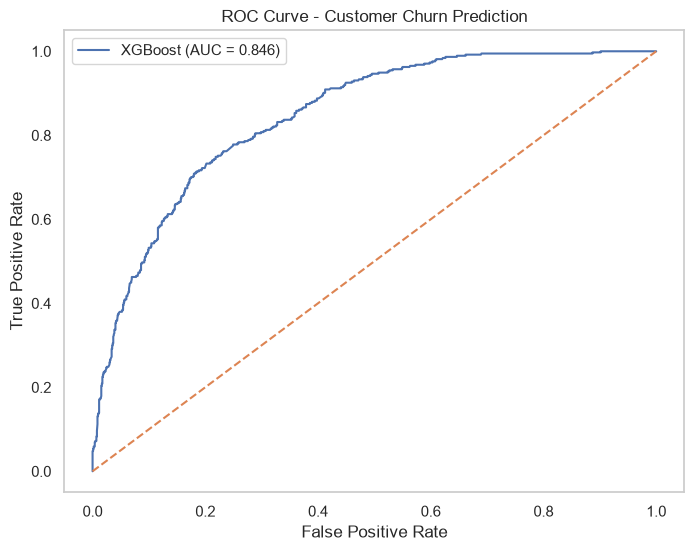

ROC-AUC: 0.8457219251336898


In [170]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", roc_auc)

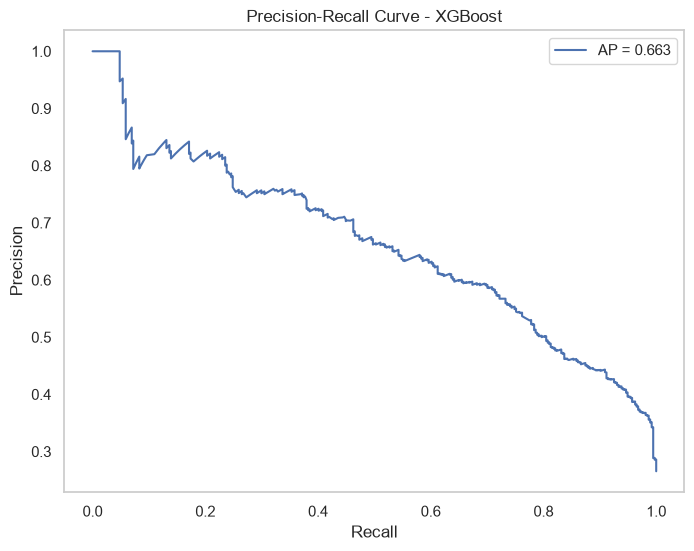

Average Precision: 0.6627923818381413


In [171]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob
)

ap_score = average_precision_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(recall, precision, label=f"AP = {ap_score:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - XGBoost")
plt.legend()
plt.grid()
plt.show()

print("Average Precision:", ap_score)

In [172]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

final_results = pd.DataFrame([{
    "Model": "XGBoost",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": ap_score
}])

display(final_results)

,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,XGBoost,0.3691,0.784954,0.576344,0.716578,0.638856,0.845722,0.662792


In [173]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_artifact = {
    "model": fitted_models["XGBoost"],
    "threshold": 0.3691
}

joblib.dump(
    model_artifact,
    "models/customer_churn_xgboost.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [179]:
with open("categorical_values.txt", "w") as f:
    for col in categorical_cols:
        f.write(f"\n{col}:\n")
        f.write(
            str(sorted(df[col].dropna().astype(str).unique()))
        )
        f.write("\n")

print("Saved categorical values to categorical_values.txt")

Saved categorical values to categorical_values.txt


In [180]:
model_features = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "tenure", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges",
    "TenureGroup", "TotalServices", "HasSupport", "HasSecurity"
]

In [181]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_artifact = {
    "model": fitted_models["XGBoost"],
    "threshold": 0.3691
}

joblib.dump(
    model_artifact,
    "models/customer_churn_xgboost.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [183]:

import joblib
from pathlib import Path

# Find the project root
project_dir = Path.cwd()

if not (project_dir / "models").exists():
    if (project_dir.parent / "models").exists():
        project_dir = project_dir.parent
    else:
        raise FileNotFoundError(
            "Could not find the project models folder."
        )

# Save model and threshold
model_artifact = {
    "model": fitted_models["XGBoost"],
    "threshold": 0.3691
}

model_path = project_dir / "models" / "customer_churn_xgboost.pkl"

joblib.dump(model_artifact, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)


Model saved successfully!
Saved location: c:\Users\hp.LAPTOP-49EU1JM8\Downloads\customer_churn\notebooks\models\customer_churn_xgboost.pkl
